# Классификация кредитного риска: Credit Risk Dataset

**Credit Risk Dataset** имитирует сведения кредитного бюро. Цель анализа - по характеристикам заёмщика и кредита предсказать `loan_status`, то есть наличие дефолта.

Тип задачи - **бинарной классификации**:

- `loan_status = 0` - кредит выплачен;
- `loan_status = 1` - зафиксирован дефолт.

Датасет: 32 581 запись** - 11 признаков и целевая переменная. 

| Признак | Описание |
|---|---|
| `person_age` | Возраст заёмщика |
| `person_income` | Годовой доход заёмщика |
| `person_home_ownership` | Тип владения жильём: аренда, ипотека, собственное жильё и др. |
| `person_emp_length` | Стаж работы в годах |
| `loan_intent` | Цель кредита |
| `loan_grade` | Кредитный рейтинг, присвоенный кредитором (от A до G) |
| `loan_amnt` | Запрошенная сумма кредита |
| `loan_int_rate` | Процентная ставка по кредиту |
| `loan_status` | **Целевая переменная:** `0` - нет дефолта, `1` - дефолт |
| `loan_percent_income` | Доля дохода, направляемая на выплаты по кредиту |
| `cb_person_default_on_file` | Наличие прошлых дефолтов в кредитной истории (`Y`/`N`) |
| `cb_person_cred_hist_length` | Длина кредитной истории в годах |


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from IPython.display import display

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             recall_score, roc_auc_score, ConfusionMatrixDisplay,
                             classification_report)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 0. Настройки (`CONFIG`)

In [8]:
CSV_PATH = 'credit_risk_dataset.csv'          # путь к файлу
SEP = ';'                                     # разделитель столбцов
TARGET = 'loan_status'                        # имя столбца с классом
POSITIVE_CLASS = 1                            # положительный класс 
MISSING_MARKERS = ['?', 'NA', 'N/A', 'NaN', 'nan', 'null', '']   # пропуски
DROP_DUPLICATES = True         # убрать дубли
TEST_SIZE = 0.25               # доля тестовой выборки
MAX_PLOTS = 12                 # максимум графиков

# невозможные значения
AGE_MIN, AGE_MAX = 18, 100     # допустимый возраст заёмщика, лет
MIN_WORK_AGE = 14              # раньше этого возраста трудового стажа быть не может
MIN_CREDIT_AGE = 16            # раньше этого возраста кредитной истории быть не может

## 1. Прочитать данные

In [9]:
data_raw = pd.read_csv(CSV_PATH, sep=SEP, na_values=MISSING_MARKERS, skipinitialspace=True, decimal=',')
data_raw.columns = data_raw.columns.str.strip()
print('Размер таблицы:', data_raw.shape)
data_raw.head(10)

Размер таблицы: (32581, 12)


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4
5,21,9900,OWN,2.0,VENTURE,A,2500,7.14,1,0.25,N,2
6,26,77100,RENT,8.0,EDUCATION,B,35000,12.42,1,0.45,N,3
7,24,78956,RENT,5.0,MEDICAL,B,35000,11.11,1,0.44,N,4
8,24,83000,RENT,8.0,PERSONAL,A,35000,8.90,1,0.42,N,2
9,21,10000,OWN,6.0,VENTURE,D,1600,14.74,1,0.16,N,3


In [10]:
data_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  str    
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  str    
 5   loan_grade                  32581 non-null  str    
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  str    
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), str(4)
memory usage: 3.0 MB


Выставялем категориальные признаки:

In [11]:
data_raw['person_home_ownership'] = data_raw['person_home_ownership'].astype('category')
data_raw['loan_intent'] = data_raw['loan_intent'].astype('category')
data_raw['loan_grade'] = data_raw['loan_grade'].astype('category')
data_raw['person_emp_length'] = data_raw['person_emp_length'].astype('Int64') # тут есть NaN поэтому force Int64

data_raw['cb_person_default_on_file'] = data_raw['cb_person_default_on_file'].astype('category') # он вообще бинарный, потом учтём
data_raw['loan_status'] = data_raw['loan_status'].astype('int8') 

data_raw.info()
data_raw.sample(3)
data_raw['loan_intent'].dtype

<class 'pandas.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype   
---  ------                      --------------  -----   
 0   person_age                  32581 non-null  int64   
 1   person_income               32581 non-null  int64   
 2   person_home_ownership       32581 non-null  category
 3   person_emp_length           31686 non-null  Int64   
 4   loan_intent                 32581 non-null  category
 5   loan_grade                  32581 non-null  category
 6   loan_amnt                   32581 non-null  int64   
 7   loan_int_rate               29465 non-null  float64 
 8   loan_status                 32581 non-null  int8    
 9   loan_percent_income         32581 non-null  float64 
 10  cb_person_default_on_file   32581 non-null  category
 11  cb_person_cred_hist_length  32581 non-null  int64   
dtypes: Int64(1), category(4), float64(2), int64(4), int8(1)
memory usage: 1.9 MB


CategoricalDtype(categories=['DEBTCONSOLIDATION', 'EDUCATION', 'HOMEIMPROVEMENT',
                  'MEDICAL', 'PERSONAL', 'VENTURE'],
, ordered=False, categories_dtype=str)

In [12]:
print('Дублей: ', data_raw.duplicated().sum())
print('Пропусков в классе (целевой переменной):', data_raw[TARGET].isna().sum())

Дублей:  165
Пропусков в классе (целевой переменной): 0


Удаляем полные дубликаты до разбиения на обучающую и тестовую выборки. Так одинаковые записи не попадут одновременно в `train` и `test`.


In [13]:
data = data_raw.drop_duplicates()
data = data.reset_index(drop=True)
print('После очистки:', data.shape)

После очистки: (32416, 12)


In [14]:
y = data[TARGET].to_numpy()     # знаечние функции
X = data.drop(columns=[TARGET]) # вектор признаков

N_CLASSES = 2
class_names = ['payed_off', 'default']

print('Классы:', dict(enumerate(class_names)))
print('Число признаков:', X.shape[1])

print(data[TARGET].isna().sum()) # смотрим, что нет пропусков 

Классы: {0: 'payed_off', 1: 'default'}
Число признаков: 11
0


### Фильтрация по бизнес-ограничениям

В данных есть записи, которые точно не могут быть правдой: это ошибки ввода, такие строки удаляем.
Правила заданы в конфиге.
- возраст заёмщика от 18 до 100 лет;
- стаж не отрицательный и не больше `возраст - 14`;
- кредитная история не длиннее `возраст - 16`;
- доход, сумма кредита и процентная ставка положительные (ставка не больше 100%);
- доля дохода `loan_percent_income` от 0 до 1.

In [15]:
age = data['person_age']
emp = data['person_emp_length']
hist = data['cb_person_cred_hist_length']

# True = строка нарушает правило
bad = pd.DataFrame({
    f'возраст вне [{AGE_MIN}; {AGE_MAX}]': (age < AGE_MIN) | (age > AGE_MAX),
    f'стаж < 0 или > возраст - {MIN_WORK_AGE}': (emp < 0) | (emp > age - MIN_WORK_AGE),
    f'кред. история > возраст - {MIN_CREDIT_AGE}': hist > age - MIN_CREDIT_AGE,
    'доход <= 0': data['person_income'] <= 0,
    'сумма кредита <= 0': data['loan_amnt'] <= 0,
    'ставка вне (0; 100]': (data['loan_int_rate'] <= 0) | (data['loan_int_rate'] > 100),
    'доля дохода вне [0; 1]': (data['loan_percent_income'] < 0) | (data['loan_percent_income'] > 1),
})
bad = bad.fillna(False).astype(bool)   # NaN потом уберём

print('Нарушений по каждому правилу:')
print(bad.sum())
print('Строк с нарушением хотя бы одного правила:', bad.any(axis=1).sum())

display(data.loc[bad.any(axis=1), ['person_age', 'person_income', 'person_emp_length', 'cb_person_cred_hist_length']])

data = data[~bad.any(axis=1)].reset_index(drop=True)
print('После фильтрации:', data.shape)

Нарушений по каждому правилу:
возраст вне [18; 100]           5
стаж < 0 или > возраст - 14     2
кред. история > возраст - 16    0
доход <= 0                      0
сумма кредита <= 0              0
ставка вне (0; 100]             0
доля дохода вне [0; 1]          0
dtype: int64
Строк с нарушением хотя бы одного правила: 7


,person_age,person_income,person_emp_length,cb_person_cred_hist_length
0,22,59000,123,3
81,144,250000,4,3
183,144,200000,4,2
210,21,192000,123,4
575,123,80004,2,3
747,123,78000,7,4
32132,144,6000000,12,25


После фильтрации: (32409, 12)


## 2. Обучающая и тестовая выборки

Разделим данные на обучающую (`train`, 75%) и тестовую (`test`, 25%) выборки. Используем стратификацию по `loan_status`, чтобы сохранить доли обоих классов в обеих частях данных.

Параметры обработки данных (границы обрезки, значения для заполнения пропусков etc) рассчитываем на `X_train` и затем применяем к `X_test`. Тестовая выборка не участвует в подборе параметров модели.


In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y)

N_train, attr = X_train.shape
N_test = X_test.shape[0]
print('train:', N_train, ' test:', N_test, ' признаков:', attr)
print('Доли классов  train:', np.round(np.bincount(y_train) / N_train, 3),
      ' test:', np.round(np.bincount(y_test) / N_test, 3))

train: 24312  test: 8104  признаков: 11
Доли классов  train: [0.781 0.219]  test: [0.781 0.219]


## 3. Визуализация и основные характеристики обучающей выборки

Анализ проводится на `train`. Это позволяет изучить параметры, не используя тестовые данные для принятия решений о подготовке модели.


In [17]:
eda = X_train.copy()
eda[TARGET] = np.array(class_names)[y_train]      # подписи классов для графиков

# для сетки графиков
def plot_grid(n, ncols=3, size=(4.6, 3.3)):
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(size[0] * ncols, size[1] * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes[n:]:
        ax.axis('off')
    return fig, axes[:n]

### Баланс классов

,число,доля
payed_off,18995,0.781
default,5317,0.219


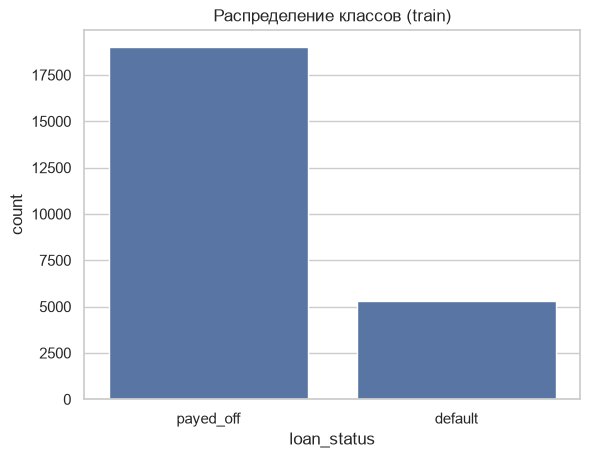

In [18]:
counts = pd.Series(np.array(class_names)[y_train]).value_counts()
display(pd.DataFrame({'число': counts, 'доля': (counts / counts.sum()).round(3)}))
sns.countplot(x=TARGET, data=eda, order=counts.index)
plt.title('Распределение классов (train)')
plt.show()

### Числовые признаки: сводка и распределения

In [19]:
numerical_cols = eda.select_dtypes(include='number').columns
for col in numerical_cols:
    print(col, eda[col].dtype)

person_age int64
person_income int64
person_emp_length Int64
loan_amnt int64
loan_int_rate float64
loan_percent_income float64
cb_person_cred_hist_length int64


In [20]:
X_train[numerical_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
person_age,24312.0,27.726061,6.30961,20.0,23.0,26.0,30.0,144.0
person_income,24312.0,65845.06215,63328.091685,4000.0,38400.0,55000.0,79000.0,6000000.0
person_emp_length,23645.0,4.767266,4.153797,0.0,2.0,4.0,7.0,123.0
loan_amnt,24312.0,9612.725197,6299.162397,500.0,5000.0,8000.0,12375.0,35000.0
loan_int_rate,21978.0,11.022595,3.234151,5.42,7.9,10.99,13.48,23.22
loan_percent_income,24312.0,0.170807,0.106674,0.0,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,24312.0,5.79689,4.041795,2.0,3.0,4.0,8.0,30.0


In [21]:
cls0, cls1 = class_names[0], class_names[1]

print(f'=== Класс 0 ({cls0}) ===')
display(eda.loc[eda[TARGET] == cls0, numerical_cols].describe().T)

print(f'=== Класс 1 ({cls1}) ===')
display(eda.loc[eda[TARGET] == cls1, numerical_cols].describe().T)

=== Класс 0 (payed_off) ===


,count,mean,std,min,25%,50%,75%,max
person_age,18995.0,27.789418,6.314565,20.0,23.0,26.0,30.0,144.0
person_income,18995.0,70505.04617,68257.56414,7000.0,42000.0,60000.0,84000.0,6000000.0
person_emp_length,18542.0,4.947039,4.127975,0.0,2.0,4.0,7.0,123.0
loan_amnt,18995.0,9249.514346,6001.268972,500.0,5000.0,8000.0,12000.0,35000.0
loan_int_rate,17171.0,10.453125,2.982182,5.42,7.74,10.62,12.69,21.74
loan_percent_income,18995.0,0.14943,0.087335,0.0,0.08,0.13,0.2,0.83
cb_person_cred_hist_length,18995.0,5.82548,4.019711,2.0,3.0,4.0,8.0,30.0


=== Класс 1 (default) ===


,count,mean,std,min,25%,50%,75%,max
person_age,5317.0,27.499718,6.287255,20.0,23.0,26.0,30.0,70.0
person_income,5317.0,49197.253903,36589.565604,4000.0,30000.0,41496.0,59475.0,703800.0
person_emp_length,5103.0,4.114051,4.182143,0.0,1.0,3.0,6.0,123.0
loan_amnt,5317.0,10910.29716,7115.03501,900.0,5000.0,9950.0,15000.0,35000.0
loan_int_rate,4807.0,13.05679,3.28029,5.42,10.75,13.49,15.58,23.22
loan_percent_income,5317.0,0.247179,0.131609,0.01,0.14,0.24,0.34,0.78
cb_person_cred_hist_length,5317.0,5.694753,4.118486,2.0,3.0,4.0,8.0,30.0


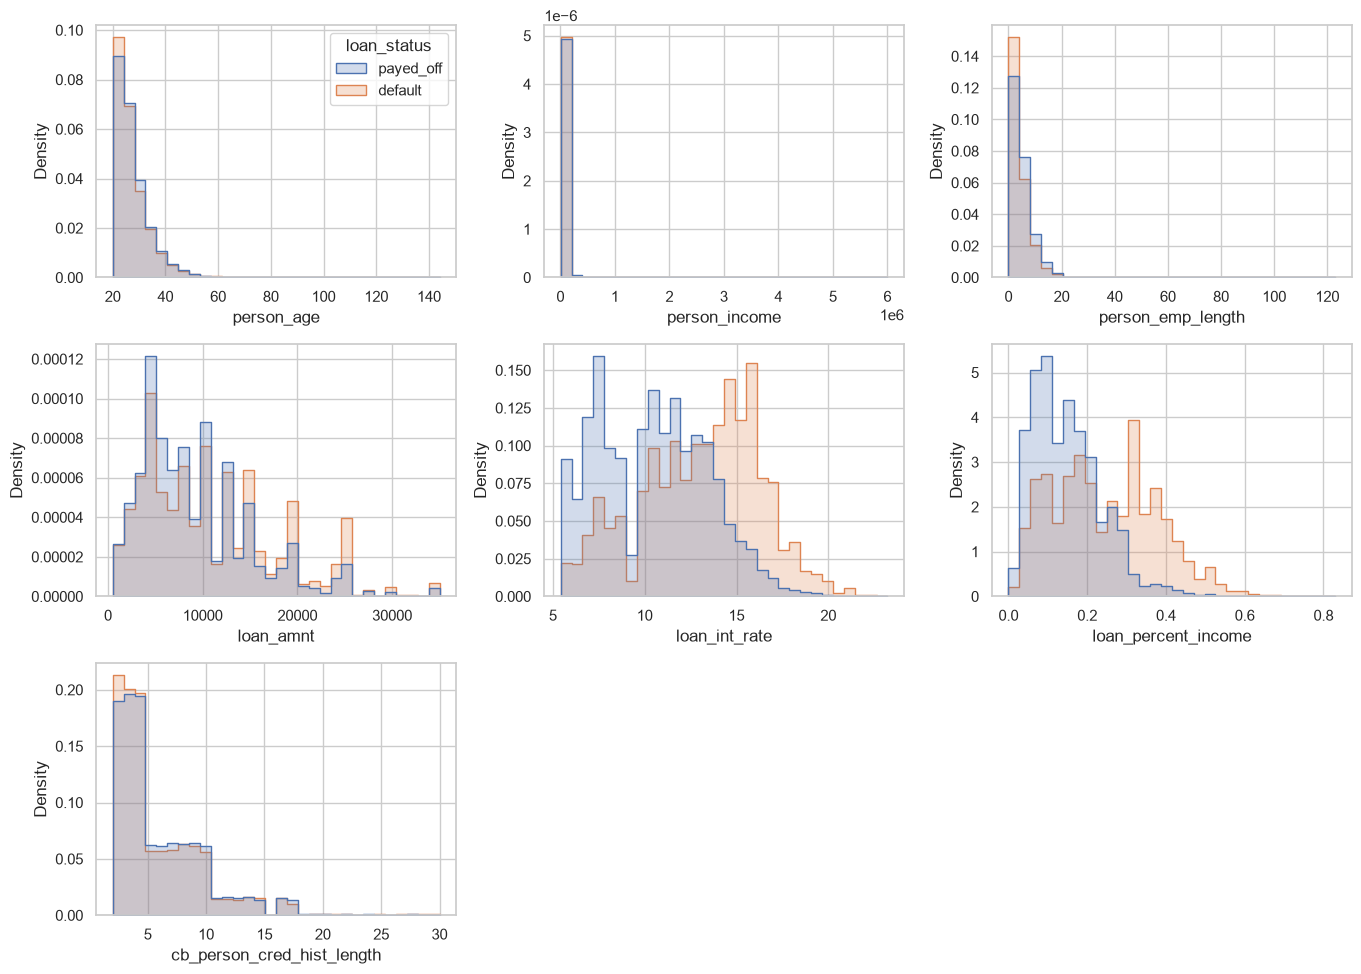

In [22]:
cols = numerical_cols
fig, axes = plot_grid(len(cols))
for ax, c in zip(axes, cols):
    sns.histplot(data=eda, x=c, hue=TARGET, bins=30, element='step',
                 stat='density', common_norm=False, ax=ax, legend=(c == cols[0]))
plt.tight_layout()
plt.show()

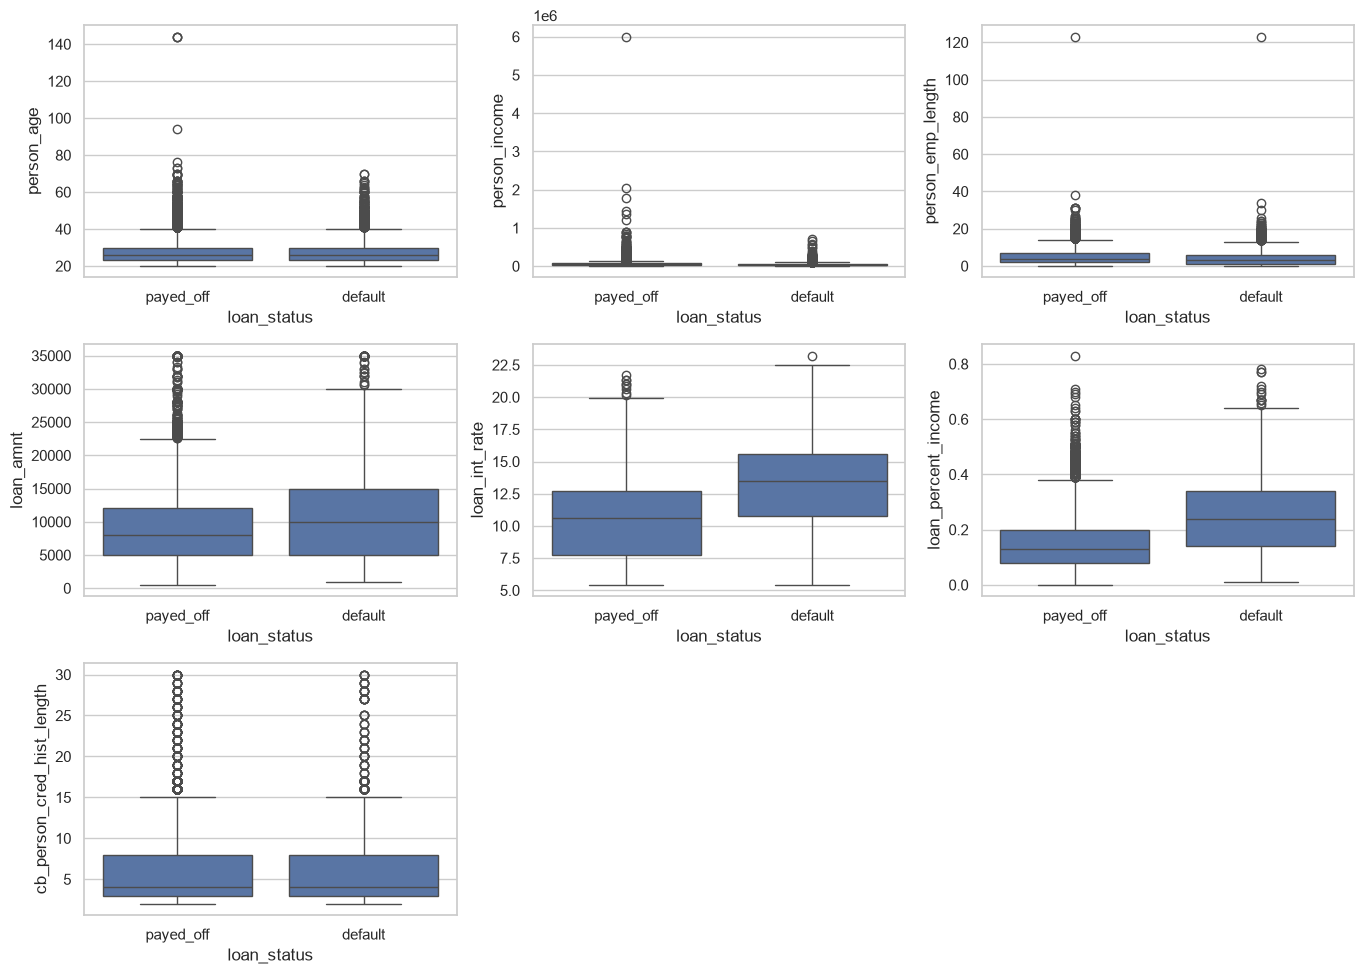

In [23]:
fig, axes = plot_grid(len(cols))
for ax, c in zip(axes, cols):
    sns.boxplot(data=eda, x=TARGET, y=c, ax=ax)
plt.tight_layout()
plt.show()

### Категориальные признаки

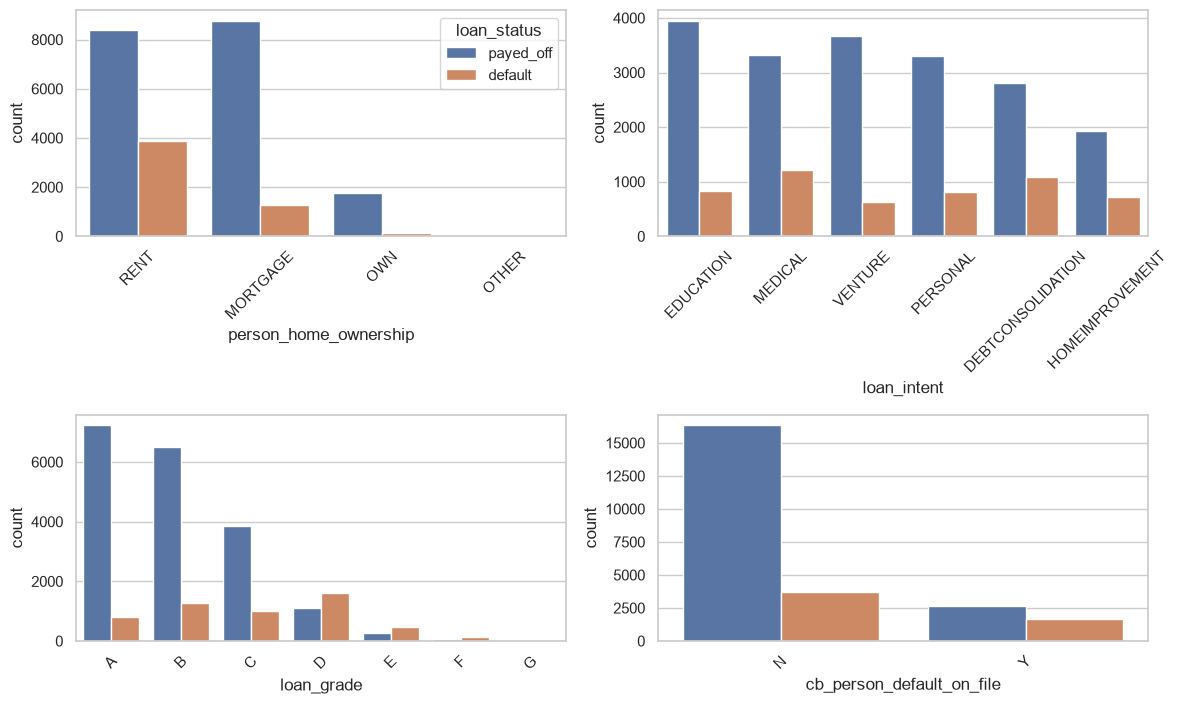

In [24]:
cat_cols = eda.select_dtypes(include='category').columns.tolist()

if len(cat_cols) > 0:                                            
    cats = cat_cols[:MAX_PLOTS]
    if cats:
        fig, axes = plot_grid(len(cats), ncols=2, size=(6, 3.6))
        for ax, c in zip(axes, cats):
            order = X_train[c].value_counts().index
            sns.countplot(data=eda, x=c, hue=TARGET, order=order, ax=ax,
                          legend=(c == cats[0]))
            ax.tick_params(axis='x', rotation=45)
        plt.tight_layout()
        plt.show()

### Корреляционная матрица

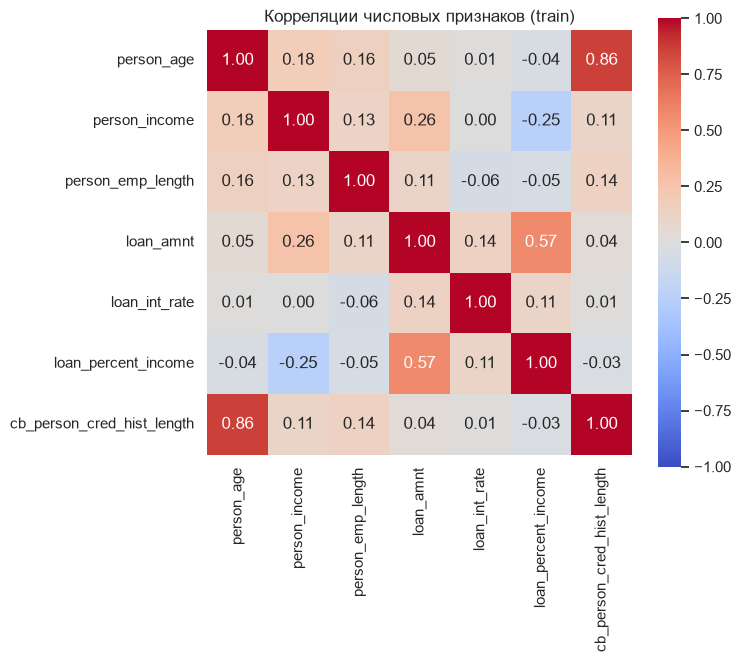

In [25]:
corr = X_train[numerical_cols].corr()
size = max(5, 0.55 * len(numerical_cols) + 3)
plt.figure(figsize=(size, size * 0.85))
sns.heatmap(corr, annot=len(numerical_cols) <= 12, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm', square=True)
plt.title('Корреляции числовых признаков (train)')
plt.show()

In [26]:
HIGH_CORR = 0.7
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
high_pairs = upper[upper.abs() > HIGH_CORR].sort_values(key=np.abs, ascending=False)
print(f'Пары числовых признаков с |corr| > {HIGH_CORR}:')
high_pairs if len(high_pairs) else print('нет')

Пары числовых признаков с |corr| > 0.7:


person_age  cb_person_cred_hist_length    0.861155
dtype: float64

### Интерпретация результатов 

- **Баланс классов.** В обучающей выборке 18 995 объектов класса 0 (78.1%) и 5 317 объектов класса 1 (21.9%). Класс без дефолта встречается примерно в 3.6 раза чаще.
- **Числовые признаки.** Медиана `loan_percent_income` выше у заёмщиков с дефолтом: около 0.24 против 0.13. Медиана `loan_int_rate` также выше: примерно 13.5 против 10.6. Медианный `person_income`, напротив, ниже у класса с дефолтом: около 41 000 против 60 000.
- **Корреляции признаков.** Наиболее сильная корреляция между числовыми признаками - у `person_age` и `cb_person_cred_hist_length` (около 0.86), что логично: с возрастом обычно увеличивается возможная длина кредитной истории. Между `loan_amnt` и `loan_percent_income` корреляция умеренная (около 0.57).
- **Категориальные признаки.** 
  - Жильё: В основном дефолт допускают с арендованным жильём, при чём количество человек с ипотекой и арендованным жильём, недопустивших дефолта примерно равное
  - Цель кредита: Больше всего дефолтов при консолидации и на медицину.
  - Рейтинг `loan_grade`: резкий скачок начиная с C. Шансы на выплату многократно выше у людей с таким рейтингом.
  - Дефолт в кредитной истории (`cb_person_default_on_file`): По соотношению видно, что люди, допустившие дефолт когда-то чаще допускают его вновь.

## 4. Выбросы и экстремальные значения

Сначала посмотрим на распределения числовых признаков и оценим количество значений за пределами правила Тьюки: ниже `Q1 - 1.5 · IQR` или выше `Q3 + 1.5 · IQR`. Эти значения не обязательно являются ошибками: среди них могут быть как некорректные данные, так и редкие, но правдоподобные наблюдения.


In [27]:
Xn = X_train[numerical_cols]
q = Xn.quantile([0.005, 0.01, 0.25, 0.5, 0.75, 0.99, 0.995]).T
Q1, Q3 = q[0.25], q[0.75]
IQR = Q3 - Q1
outside = (Xn.lt(Q1 - 1.5 * IQR) | Xn.gt(Q3 + 1.5 * IQR)).mean() * 100

report = pd.concat([Xn.min().rename('min'), q, Xn.max().rename('max'),
                    outside.rename('% вне *усов* Тьюки').round(2)], axis=1)
report

,min,0.005,0.01,0.25,0.5,0.75,0.99,0.995,max,% вне *усов* Тьюки
person_age,20.0,21.0,21.0,23.0,26.0,30.0,50.0,54.0,144.0,4.58
person_income,4000.0,12000.0,14400.0,38400.0,55000.0,79000.0,225000.0,288000.0,6000000.0,4.93
person_emp_length,0.0,0,0,2,4,7,17,19,123.0,2.65
loan_amnt,500.0,1000.0,1077.75,5000.0,8000.0,12375.0,28000.0,35000.0,35000.0,5.05
loan_int_rate,5.42,5.42,5.42,7.9,10.99,13.48,18.43,19.29,23.22,0.01
loan_percent_income,0.0,0.02,0.02,0.09,0.15,0.23,0.5,0.53,0.83,2.01
cb_person_cred_hist_length,2.0,2.0,2.0,3.0,4.0,8.0,17.0,22.445,30.0,3.49


**Обработка экстремальных значений.** Строки не удаляем: на практике модель может получить похожие данные, поэтому удаление таких объектов способно исказить задачу. 
Вместо этого обрезаем числовые признаки по нижнему `quantile(0.01)` и верхнему `quantile(0.995)`. Границы рассчитываются только на `X_train`, а затем одинаково применяются к `X_train` и `X_test`. 


In [28]:

before = X_train[numerical_cols].copy()
lo = X_train[numerical_cols].quantile(0.01)
hi = X_train[numerical_cols].quantile(0.995)

X_train[numerical_cols] = X_train[numerical_cols].clip(lo, hi, axis=1)
X_test[numerical_cols]  = X_test[numerical_cols].clip(lo, hi, axis=1)
pd.DataFrame({'min до': before.min(), 'min после': X_train[numerical_cols].min(),
              'max до': before.max(), 'max после': X_train[numerical_cols].max(),
              '% обрезано': (before.ne(X_train[numerical_cols]) & before.notna()).mean().mul(100).round(2)})

,min до,min после,max до,max после,% обрезано
person_age,20.0,21.0,144.0,54.0,0.51
person_income,4000.0,14400.0,6000000.0,288000.0,1.44
person_emp_length,0.0,0.0,123.0,19.0,0.42
loan_amnt,500.0,1077.75,35000.0,35000.0,1.0
loan_int_rate,5.42,5.42,23.22,19.29,0.45
loan_percent_income,0.0,0.02,0.83,0.53,0.88
cb_person_cred_hist_length,2.0,2.0,30.0,22.445,0.5


### Интерпретация результатов анализа выбросов

- **Ошибки данных.** Явно неправдоподобные значения (eg возраст до 144 лет и стаж работы 123 года) были удалены в п. 1 как невозможные.
- **Правило Тьюки.** За его границы выходит около 2–5% значений в большинстве числовых признаков. Однако высокие доходы, суммы кредитов и длительная кредитная история могут встречаться и в реальных данных.
- **Обрезка.** Доля изменённых значений составляет примерно 0.4–1.44% для разных числовых признаков; сильнее всего обрезка затрагивает `person_income`. Применяется обрезка по границам, рассчитанным на `train`, поэтому тестовые данные не влияют на эти границы.


## 5. Пропущенные значения

Проверим пропуски отдельно в обучающей и тестовой выборках. По результатам проверки они есть в `person_emp_length` и `loan_int_rate`; целевая переменная `loan_status` пропусков не содержит.


In [29]:
miss = pd.DataFrame({'train, шт.': X_train.isna().sum(),
                     'train, %': (X_train.isna().mean() * 100).round(2),
                     'test, шт.': X_test.isna().sum()})
miss = miss[(miss['train, шт.'] > 0) | (miss['test, шт.'] > 0)]
if len(miss):
    display(miss)
else:
    print('Пропусков нет')

,"train, шт.","train, %","test, шт."
person_emp_length,667,2.74,220
loan_int_rate,2334,9.60,761


Для числовых признаков используем медиану обучающей выборки, а для категориальных - моду.


In [30]:
fill_values = X_train[numerical_cols].median()
if cat_cols:
    fill_values = pd.concat([fill_values, X_train[cat_cols].mode().iloc[0]])

X_train = X_train.fillna(fill_values)
X_test  = X_test.fillna(fill_values)

print('Пропусков осталось: train', X_train.isna().sum().sum(), ' test', X_test.isna().sum().sum())
fill_values[miss.index]

Пропусков осталось: train 0  test 0


person_emp_length      4.0
loan_int_rate        10.99
dtype: object

## 6. Кодирование категориальных признаков

Категориальные столбцы преобразуем с помощью `OneHotEncoder`. В наборе четыре категориальных признака: `person_home_ownership`, `loan_intent`, `loan_grade` и `cb_person_default_on_file`.

Кодирование создаёт **18 dummy-столбцов**; общее число признаков увеличивается с 11 до 25. Для бинарного признака параметр `drop='if_binary'` оставляет один столбец: второй класс можно однозначно восстановить по нулю в этом столбце. Кодировщик обучается только на `X_train`, а затем преобразует обе выборки.


In [31]:
print('Категориальные признаки:', cat_cols)
features_before = X_train.shape[1]

encoder = OneHotEncoder(
    drop='if_binary',
    handle_unknown='ignore',
    sparse_output=False
)
encoder.fit(X_train[cat_cols])

# категориальные в dummy
dummy_columns = encoder.get_feature_names_out(cat_cols)
dummies_train = pd.DataFrame(
    encoder.transform(X_train[cat_cols]),
    columns=dummy_columns,
    index=X_train.index
)
dummies_test = pd.DataFrame(
    encoder.transform(X_test[cat_cols]),
    columns=dummy_columns,
    index=X_test.index
)

# add dummy, rm исходные категориальные признаки
X_train = pd.concat([X_train.drop(columns=cat_cols), dummies_train], axis=1)
X_test = pd.concat([X_test.drop(columns=cat_cols), dummies_test], axis=1)

print('Признаков до кодирования:', features_before)
print('Создано dummy-столбцов:', len(dummy_columns))
print('Признаков после кодирования:', X_train.shape[1])
display(dummies_train.head())
display(X_train.head())


Категориальные признаки: ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
Признаков до кодирования: 11
Создано dummy-столбцов: 18
Признаков после кодирования: 25


,person_home_ownership_MORTGAGE,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,loan_grade_A,loan_grade_B,loan_grade_C,loan_grade_D,loan_grade_E,loan_grade_F,loan_grade_G,cb_person_default_on_file_Y
25859,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
11136,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
24217,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
10759,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
23899,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,person_home_ownership_MORTGAGE,person_home_ownership_OTHER,person_home_ownership_OWN,...,loan_intent_PERSONAL,loan_intent_VENTURE,loan_grade_A,loan_grade_B,loan_grade_C,loan_grade_D,loan_grade_E,loan_grade_F,loan_grade_G,cb_person_default_on_file_Y
25859,28.0,62000.0,2,12800.0,13.16,0.21,5.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
11136,24.0,50000.0,1,10000.0,7.51,0.20,4.0,0.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
24217,29.0,48000.0,13,10000.0,7.51,0.21,7.0,0.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
10759,23.0,34000.0,7,10000.0,10.36,0.29,4.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
23899,28.0,63000.0,5,9000.0,13.72,0.14,9.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


## 7. Нормализация признаков

`StandardScaler` центрирует признаки (вычитает среднее) и масштабирует их по стандартному отклонению. 

Масштабирование применяется после onehot кодирования ко всем 25 признакам, включая dummy-столбцы. `StandardScaler` обучается только на `X_train`; к `X_test` применяется то же преобразование.


In [32]:
scaler = StandardScaler()
scaler.fit(X_train)

X_train = pd.DataFrame(
    scaler.transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)
X_test = pd.DataFrame(
    scaler.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

display(X_train.head())


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,person_home_ownership_MORTGAGE,person_home_ownership_OTHER,person_home_ownership_OWN,...,loan_intent_PERSONAL,loan_intent_VENTURE,loan_grade_A,loan_grade_B,loan_grade_C,loan_grade_D,loan_grade_E,loan_grade_F,loan_grade_G,cb_person_default_on_file_Y
25859,0.052474,-0.068146,-0.69974,0.505950,0.700017,0.374457,-0.196938,-0.838023,-0.058174,-0.291911,...,-0.451181,-0.464327,-0.702466,-0.685227,1.995998,-0.352202,-0.175071,-0.087327,-0.042093,2.156084
11136,-0.612238,-0.369541,-0.95672,0.061350,-1.144338,0.279553,-0.450519,-0.838023,-0.058174,-0.291911,...,-0.451181,-0.464327,1.423557,-0.685227,-0.501002,-0.352202,-0.175071,-0.087327,-0.042093,-0.463804
24217,0.218652,-0.419774,2.12704,0.061350,-1.144338,0.374457,0.310226,-0.838023,-0.058174,-0.291911,...,2.216405,-0.464327,1.423557,-0.685227,-0.501002,-0.352202,-0.175071,-0.087327,-0.042093,-0.463804
10759,-0.778416,-0.771402,0.58516,0.061350,-0.213999,1.133694,-0.450519,-0.838023,-0.058174,-0.291911,...,-0.451181,-0.464327,-0.702466,1.459371,-0.501002,-0.352202,-0.175071,-0.087327,-0.042093,-0.463804
23899,0.052474,-0.043030,0.07120,-0.097435,0.882821,-0.289874,0.817389,1.193285,-0.058174,-0.291911,...,-0.451181,-0.464327,-0.702466,-0.685227,1.995998,-0.352202,-0.175071,-0.087327,-0.042093,2.156084


**Итог предобработки.** Четыре категориальных признака заменены 18 dummy; теперь в данных 25 числовых признаков. Пропуски заполнены медианами (для числовых столбцов) или модой (для категориальных), экстремальные значения числовых признаков ограничены квантилями. Кодировщик и `StandardScaler` обучены на `train`, чтобы информация из тестовой выборки не использовалась при настройке преобразований.


## 8. Классификатор ближайших соседей и выбор $k$

Используем **kNN** (`KNeighborsClassifier`) -  классификатор, который относит объект к наиболее частому классу среди его $k$ ближайших соседей.

Классы несбалансированы (примерно 78% класса 0 и 22% класса 1), поэтому выбираем $k$ по `balanced accuracy` - среднему значению полноты по двум классам. В отличие от обычной `accuracy`, эта метрика учитывает качество распознавания каждого класса, а не позволяет более многочисленному классу полностью определять итоговый результат.

Проверяем значения $k \in \{1, 3, 5, 7, 9, 11, 15, 21, 31, 41, 51\}$ с помощью стратифицированной 5-блочной кросс-валидации на обучающей выборке. Для бинарной классификации используются нечётные значения $k$, чтобы снизить вероятность ничьей при голосовании соседей.

In [33]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# проверяем нечётные k
k_arr = np.array([1, 3, 5, 7, 9, 11, 15, 21, 31, 41, 51])

grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid={'n_neighbors': k_arr},
    scoring='balanced_accuracy',
    cv=cv,
    return_train_score=True,
    n_jobs=-1
)
grid.fit(X_train, y_train)

best_k = grid.best_params_['n_neighbors']
print('Лучшее k =', best_k)
print(f'Лучшая balanced accuracy по CV = {grid.best_score_:.4f}')
print(f'Сбалансированная ошибка по CV = {1 - grid.best_score_:.4f}')


Лучшее k = 3
Лучшая balanced accuracy по CV = 0.7945
Сбалансированная ошибка по CV = 0.2055


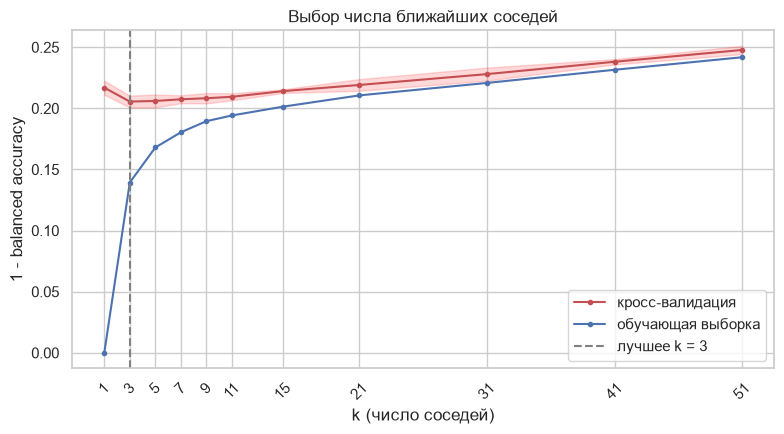

In [34]:
balanced_error_cv = 1 - grid.cv_results_['mean_test_score']
std_cv = grid.cv_results_['std_test_score']
balanced_error_train = 1 - grid.cv_results_['mean_train_score']

plt.figure(figsize=(8, 4.5))
plt.plot(k_arr, balanced_error_cv, 'r.-', label='кросс-валидация')
plt.fill_between(
    k_arr,
    balanced_error_cv - std_cv,
    balanced_error_cv + std_cv,
    alpha=0.15,
    color='red'
)
plt.plot(k_arr, balanced_error_train, 'b.-', label='обучающая выборка')
plt.axvline(best_k, color='gray', ls='--', label=f'лучшее k = {best_k}')
plt.xticks(k_arr, rotation=45)
plt.xlabel('k (число соседей)')
plt.ylabel('1 - balanced accuracy')
plt.title('Выбор числа ближайших соседей')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


### Интерпретация выбора $k$

Кросс-валидация выбрала $k = 3$. Лучшая средняя `balanced accuracy` равна 0.7945, то есть сбалансированная ошибка `1 - balanced accuracy` составляет 0.2055.

На графике при $k = 1$ ошибка на обучающих данных практически нулевая, тогда как ошибка кросс-валидации заметно выше - признак переобучения ближайшего соседа. При $k = 3$ CV-ошибка достигает минимума среди проверенных значений. 

При дальнейшем увеличении $k$ ошибка постепенно растёт: граница решения становится более сглаженной. Различие между соседними малыми значениями $k$ невелико, поэтому преимущество $k=3$ по CV есть.


### Почему выбран метод ближайших соседей

В пользу kNN для этой задачи:

1. **Не предполагает форму зависимости.** Метод непараметрический: не требует линейной границы между классами или определённого вида распределений. Для кредитного риска это удобно: признаки взаимодействуют, и заранее неизвестно, какой формы будет граница.
2. **Данные уже подготовлены под метод.** После one-hot кодирования и стандартизации все 25 признаков числовые и в сопоставимых масштабах, поэтому евклидово расстояние имеет смысл. 
3. **Размер задачи подходит.** Около 24 тыс. объектов и 25 признаков: пространство не настолько многомерное, чтобы расстояния «размывались», а предсказание считается за секунды.
4. **Решение объяснимо по аналогии.** «Заёмщик похож на тех, кто раньше чаще (или реже) допускал дефолт» - это близко к логике кредитного аналитика, и для любого объекта можно показать конкретных соседей.
5. **Один гиперпараметр.** Сложность модели регулируется только числом соседей $k$, и его честно выбирает кросс-валидация: $k = 1$ переобучается, большие $k$ чрезмерно сглаживают.

Ограничения метода, которые учитываем:

- чувствительность к шуму и выбросам - поэтому до модели удалены невозможные значения, остальные экстремумы обрезаны
- дисбаланс классов смещает голосование соседей в сторону класса 0 - поэтому $k$ выбираем по `balanced accuracy`, а качество смотрим по `recall` дефолтов;
- у kNN нет оценки важности признаков.


## 9. Ошибки на обучающей и тестовой выборках

После выбора $k$ оцениваем лучшую модель на `train` и `test`. Доля ошибок классификации определяется как $E = 1 - accuracy$ - это доля объектов, для которых предсказанный класс не совпал с истинным.

В матрице рассогласования строки соответствуют истинному классу, столбцы - предсказанному.

Выбранное число соседей k = 3
--- Обучающая выборка ---
Ошибки классификации: 1691 из 24312 (6.9554%)
Accuracy:          0.9304
Balanced accuracy: 0.8635
F1 для класса 1:   0.8240
Recall класса 1:   0.7446
ROC-AUC:           0.9761
Отчёт по классам:
              precision    recall  f1-score   support

   payed_off       0.93      0.98      0.96     18995
     default       0.92      0.74      0.82      5317

    accuracy                           0.93     24312
   macro avg       0.93      0.86      0.89     24312
weighted avg       0.93      0.93      0.93     24312


--- Тестовая выборка ---
Ошибки классификации: 892 из 8104 (11.0069%)
Accuracy:          0.8899
Balanced accuracy: 0.7991
F1 для класса 1:   0.7170
Recall класса 1:   0.6377
ROC-AUC:           0.8475
Отчёт по классам:
              precision    recall  f1-score   support

   payed_off       0.90      0.96      0.93      6332
     default       0.82      0.64      0.72      1772

    accuracy                           0

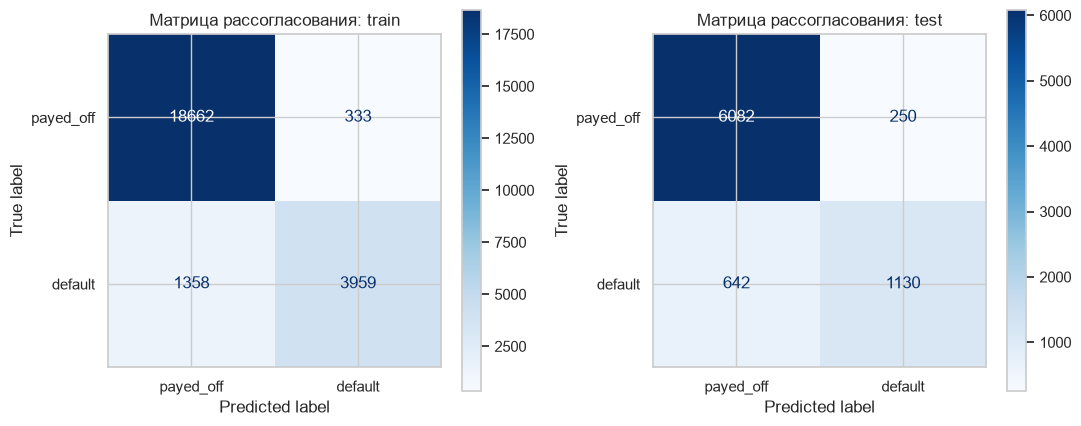

In [35]:
best_model = grid.best_estimator_

y_train_pred = best_model.predict(X_train)
y_test_pred = best_model.predict(X_test)
y_train_score = best_model.predict_proba(X_train)[:, 1]
y_test_score = best_model.predict_proba(X_test)[:, 1]

def print_metrics(split_name, y_true, y_pred, y_score):
    accuracy = accuracy_score(y_true, y_pred)
    n_errors = int(np.sum(np.asarray(y_true) != np.asarray(y_pred)))
    n_objects = len(y_true)
    print(f'--- {split_name} ---')
    print(f'Ошибки классификации: {n_errors} из {n_objects} ({1 - accuracy:.4%})')
    print(f'Accuracy:          {accuracy:.4f}')
    print(f'Balanced accuracy: {balanced_accuracy_score(y_true, y_pred):.4f}')
    print(f'F1 для класса 1:   {f1_score(y_true, y_pred, zero_division=0):.4f}')
    print(f'Recall класса 1:   {recall_score(y_true, y_pred, zero_division=0):.4f}')
    print(f'ROC-AUC:           {roc_auc_score(y_true, y_score):.4f}')
    print('Отчёт по классам:')
    print(classification_report(
        y_true, y_pred, labels=[0, 1], target_names=class_names, zero_division=0
    ))
    print()

print('Выбранное число соседей k =', best_k)
print_metrics('Обучающая выборка', y_train, y_train_pred, y_train_score)
print_metrics('Тестовая выборка', y_test, y_test_pred, y_test_score)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
ConfusionMatrixDisplay.from_predictions(
    y_train,
    y_train_pred,
    labels=[0, 1],
    display_labels=class_names,
    values_format='d',
    cmap='Blues',
    ax=axes[0]
)
axes[0].set_title('Матрица рассогласования: train')

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_test_pred,
    labels=[0, 1],
    display_labels=class_names,
    values_format='d',
    cmap='Blues',
    ax=axes[1]
)
axes[1].set_title('Матрица рассогласования: test')
plt.tight_layout()
plt.show()


## 10. Общие выводы

1. **Данные и постановка задачи**. Проанализирован `Credit Risk Dataset` автора `laotse`: после удаления 165 дубликатов осталось 32 416 наблюдений, 11 исходных признаков и целевая переменная `loan_status`. Это бинарная классификация: класс 0 - нет дефолта (78.1%), класс 1 - дефолт (21.9%). Дисбаланс классов составляет примерно 3.6 : 1.

2. **Предобработка**. В `person_emp_length` и `loan_int_rate` были пропуски; они заполнены статистиками, рассчитанными на `train` (медианы 4.0 и 10.99 соответственно). Числовые признаки обрезаны по 1-му и 99.5-му квантилям, найденным на `train`. Четыре категориальных признака преобразованы в 18 dummy-столбцов, итоговая размерность - 25 признаков. Затем выполнена стандартизация, необходимая для корректной работы расстояний в kNN.

3. **Выбор модели и гиперпараметра**. В качестве базового классификатора использован kNN. Среди проверенных значений выбрано $k=3$: средняя `balanced accuracy` по 5-блочной кросс-валидации - 0.7945, сбалансированная ошибка - 0.2055. `Balanced accuracy` выбрана из-за дисбаланса классов: она усредняет полноту для классов 0 и 1.

4. **Качество на train и test**. На обучающей выборке модель ошиблась в 1 691 случае из 24 312 (6.96%); `accuracy = 0.9304`, `balanced accuracy = 0.8635`, `F1` класса дефолта - 0.8240, `recall` дефолта - 0.7446. На тестовой выборке получено 892 ошибки из 8 104 (11.01%); `accuracy = 0.8899`, `balanced accuracy = 0.7991`, `F1` дефолта - 0.7170, `recall` дефолта - 0.6377, `ROC-AUC = 0.8475`.

5. **Матрица рассогласования на тесте**. Из 1 772 реальных дефолтов модель выявила 1 130 и пропустила 642 (FN). Среди объектов без дефолта она верно классифицировала 6 082 и ошибочно отметила 250 как дефолт (FP). Таким образом, ложноположительных ошибок меньше, чем ложноотрицательных. Модель достаточно хорошо распознаёт класс без дефолта, но пропускает около 36.2% реальных дефолтов.

6. **Обобщение и ограничения.** Результаты на обучающей выборке лучше, чем на тестовой, что указывает на разрыв обобщения и отчасти оптимистичную оценку на данных, уже использованных для обучения. При этом `balanced accuracy` на тесте (0.7991) близка к среднему результату кросс-валидации (0.7945), поэтому CV достаточно хорошо предсказала качество на отложенных данных. 
